<a href="https://colab.research.google.com/github/varsha-1428/NAFnet/blob/main/NAFNet_Official_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%cd /content

!git clone https://github.com/megvii-research/NAFNet.git

%cd /content/NAFNet

print("NAFNet repository cloned successfully!")

/content
Cloning into 'NAFNet'...
remote: Enumerating objects: 521, done.
remote: Counting objects: 100% (339/339), done.
remote: Compressing objects: 100% (116/116), done.
remote: Total 521 (delta 263), reused 223 (delta 223), pack-reused 182 (from 1)
Receiving objects: 100% (521/521), 16.19 MiB | 31.40 MiB/s, done.
Resolving deltas: 100% (279/279), done.
/content/NAFNet
NAFNet repository cloned successfully!


In [ ]:
%cd /content/NAFNet

!pip install -q -r requirements.txt

print("Dependency installation completed!")

/content/NAFNet
Dependency installation completed!


In [ ]:
%cd /content/NAFNet

import torch
import sys
import os

sys.path.insert(0, "/content/NAFNet")

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

# Test official NAFNet architecture import
from basicsr.models.archs.NAFNet_arch import NAFNet, NAFBlock

print("\nNAFNet architecture imported successfully!")

/content/NAFNet
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

NAFNet architecture imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

DATA_ROOT = "/content/drive/MyDrive/GoPro"

print("Dataset exists:", os.path.exists(DATA_ROOT))

for split in ["train", "test"]:
    path = os.path.join(DATA_ROOT, split)
    scenes = [d for d in os.listdir(path)
              if os.path.isdir(os.path.join(path, d))]

    print(f"{split}: {len(scenes)} scenes")

Dataset exists: True
train: 22 scenes
test: 11 scenes


In [ ]:
import os
from pathlib import Path

from_dir = Path("/content/drive/MyDrive/GoPro/train")
to_dir = Path("/content/NAFNet/datasets/GoPro/train")

input_dir = to_dir / "input"
target_dir = to_dir / "target"

input_dir.mkdir(parents=True, exist_ok=True)
target_dir.mkdir(parents=True, exist_ok=True)

count = 0

for scene in from_dir.iterdir():
    if not scene.is_dir():
        continue

    blur_dir = scene / "blur"
    sharp_dir = scene / "sharp"

    if not blur_dir.exists() or not sharp_dir.exists():
        continue

    for blur_img in blur_dir.iterdir():
        sharp_img = sharp_dir / blur_img.name

        if blur_img.suffix.lower() not in [".png", ".jpg", ".jpeg"]:
            continue

        if sharp_img.exists():
            # Unique filenames preserve the scene identity
            filename = f"{scene.name}_{blur_img.name}"

            os.symlink(blur_img, input_dir / filename)
            os.symlink(sharp_img, target_dir / filename)

            count += 1

print("Training pairs prepared:", count)
print("Input images:", len(list(input_dir.iterdir())))
print("Target images:", len(list(target_dir.iterdir())))

Training pairs prepared: 1605
Input images: 1605
Target images: 1605


In [ ]:
%cd /content/NAFNet

!PYTHONPATH=/content/NAFNet:$PYTHONPATH python scripts/data_preparation/gopro.py

/content/NAFNet
mkdir ./datasets/GoPro/train/blur_crops ...
Extract: 100% 1605/1605 [07:55<00:00,  3.37image/s]
All processes done.
mkdir ./datasets/GoPro/train/sharp_crops ...
Extract: 100% 1605/1605 [07:46<00:00,  3.44image/s]
All processes done.
Reading image path list ...
Create lmdb for ./datasets/GoPro/train/blur_crops, save to ./datasets/GoPro/train/blur_crops.lmdb...
Total images: 12840
Data size per image is:  295025
Write GOPR0884_11_00_000246_s008: 100% 12840/12840 [08:00<00:00, 26.71chunk/s]

Finish writing lmdb.
Reading image path list ...
Create lmdb for ./datasets/GoPro/train/sharp_crops, save to ./datasets/GoPro/train/sharp_crops.lmdb...
Total images: 12840
Data size per image is:  317042
Write GOPR0884_11_00_000246_s008: 100% 12840/12840 [08:36<00:00, 24.84chunk/s]

Finish writing lmdb.


In [ ]:
import os

base = "/content/NAFNet/datasets/GoPro/train"

for name in [
    "blur_crops",
    "sharp_crops",
    "blur_crops.lmdb",
    "sharp_crops.lmdb"
]:
    path = os.path.join(base, name)
    print(name, ":", os.path.exists(path))

blur_crops : True
sharp_crops : True
blur_crops.lmdb : True
sharp_crops.lmdb : True


In [ ]:
from pathlib import Path
import os

source = Path("/content/drive/MyDrive/GoPro/test")
destination = Path("/content/NAFNet/datasets/GoPro/test")

input_dir = destination / "input"
target_dir = destination / "target"

input_dir.mkdir(parents=True, exist_ok=True)
target_dir.mkdir(parents=True, exist_ok=True)

count = 0

for scene in source.iterdir():
    if not scene.is_dir():
        continue

    blur_dir = scene / "blur"
    sharp_dir = scene / "sharp"

    if not blur_dir.exists() or not sharp_dir.exists():
        continue

    for blur_img in blur_dir.iterdir():
        sharp_img = sharp_dir / blur_img.name

        if blur_img.suffix.lower() not in [".png", ".jpg", ".jpeg"]:
            continue

        if sharp_img.exists():
            filename = f"{scene.name}_{blur_img.name}"

            os.symlink(blur_img, input_dir / filename)
            os.symlink(sharp_img, target_dir / filename)

            count += 1

print("Test pairs prepared:", count)

Test pairs prepared: 379


In [ ]:
%cd /content/NAFNet

from basicsr.utils.lmdb_util import make_lmdb_from_imgs
from pathlib import Path

test_root = Path("./datasets/GoPro/test")

# Convert blurry input images
input_folder = str(test_root / "input")
input_lmdb = str(test_root / "input.lmdb")

input_images = sorted(
    [p.name for p in Path(input_folder).iterdir()
     if p.suffix.lower() == ".png"]
)

make_lmdb_from_imgs(
    input_folder,
    input_lmdb,
    input_images,
    [Path(p).stem for p in input_images]
)

# Convert sharp ground-truth images
target_folder = str(test_root / "target")
target_lmdb = str(test_root / "target.lmdb")

target_images = sorted(
    [p.name for p in Path(target_folder).iterdir()
     if p.suffix.lower() == ".png"]
)

make_lmdb_from_imgs(
    target_folder,
    target_lmdb,
    target_images,
    [Path(p).stem for p in target_images]
)

print("Test LMDB creation completed!")

/content/NAFNet
Create lmdb for datasets/GoPro/test/input, save to datasets/GoPro/test/input.lmdb...
Total images: 379
Data size per image is:  1085214


Write GOPR0881_11_01_000300: 100%|██████████| 379/379 [04:25<00:00,  1.43chunk/s]



Finish writing lmdb.
Create lmdb for datasets/GoPro/test/target, save to datasets/GoPro/test/target.lmdb...
Total images: 379
Data size per image is:  1098925


Write GOPR0881_11_01_000300: 100%|██████████| 379/379 [05:00<00:00,  1.26chunk/s]



Finish writing lmdb.
Test LMDB creation completed!


In [ ]:
import os

for folder in ["input.lmdb", "target.lmdb"]:
    print(folder, os.path.exists(f"./datasets/GoPro/test/{folder}"))

input.lmdb True
target.lmdb True


In [ ]:
%cd /content/NAFNet

!cat options/train/GoPro/NAFNet-width32.yml

/content/NAFNet
# ------------------------------------------------------------------------
# Copyright (c) 2022 megvii-model. All Rights Reserved.
# ------------------------------------------------------------------------
# Modified from BasicSR (https://github.com/xinntao/BasicSR)
# Copyright 2018-2020 BasicSR Authors
# ------------------------------------------------------------------------
# general settings
name: NAFNet-GoPro-width32
model_type: ImageRestorationModel
scale: 1
num_gpu: 8
manual_seed: 42

datasets:
  train:
    name: gopro-train
    type: PairedImageDataset
    dataroot_gt: ./datasets/GoPro/train/sharp_crops.lmdb
    dataroot_lq: ./datasets/GoPro/train/blur_crops.lmdb

    filename_tmpl: '{}'
    io_backend:
      type: lmdb

    gt_size: 256
    use_flip: true
    use_rot: true

    # data loader
    use_shuffle: true
    num_worker_per_gpu: 4
    batch_size_per_gpu: 4
    dataset_enlarge_ratio: 1
    prefetch_mode: ~

  val:
    name: gopro-test
    type: PairedIma

In [ ]:
%cd /content/NAFNet

import yaml
from pathlib import Path

config_path = Path("options/train/GoPro/NAFNet-width32.yml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

# New experiment name
config["name"] = "NAFNet-GoPro-width32-T4"

# Single T4 GPU
config["num_gpu"] = 1

# Keep the original NAFNet architecture unchanged
config["network_g"]["type"] = "NAFNetLocal"
config["network_g"]["width"] = 32
config["network_g"]["enc_blk_nums"] = [1, 1, 1, 28]
config["network_g"]["middle_blk_num"] = 1
config["network_g"]["dec_blk_nums"] = [1, 1, 1, 1]

# Reduce batch size for T4 memory
config["datasets"]["train"]["batch_size_per_gpu"] = 1
config["datasets"]["train"]["num_worker_per_gpu"] = 2

# Keep official 256x256 crop size
config["datasets"]["train"]["gt_size"] = 256

# Scaled training schedule
config["train"]["total_iter"] = 2000
config["train"]["scheduler"]["T_max"] = 2000

# Save and validate during the shorter run
config["logger"]["print_freq"] = 50
config["logger"]["save_checkpoint_freq"] = 500
config["val"]["val_freq"] = 500

# Keep original loss and optimizer settings
# PSNRLoss and AdamW are unchanged

new_config_path = Path(
    "options/train/GoPro/NAFNet-width32-T4.yml"
)

with open(new_config_path, "w") as f:
    yaml.dump(config, f, sort_keys=False)

print("T4 configuration created:", new_config_path)
print("Architecture:", config["network_g"])
print("Batch size:", config["datasets"]["train"]["batch_size_per_gpu"])
print("Iterations:", config["train"]["total_iter"])
print("Loss:", config["train"]["pixel_opt"]["type"])

/content/NAFNet
T4 configuration created: options/train/GoPro/NAFNet-width32-T4.yml
Architecture: {'type': 'NAFNetLocal', 'width': 32, 'enc_blk_nums': [1, 1, 1, 28], 'middle_blk_num': 1, 'dec_blk_nums': [1, 1, 1, 1]}
Batch size: 1
Iterations: 2000
Loss: PSNRLoss


In [ ]:
%cd /content/NAFNet

import yaml

config_path = "options/train/GoPro/NAFNet-width32-T4.yml"

with open(config_path, "r") as f:
    opt = yaml.safe_load(f)

# Required dataset fields
opt["datasets"]["train"]["scale"] = 1
opt["datasets"]["train"]["phase"] = "train"

opt["datasets"]["val"]["scale"] = 1
opt["datasets"]["val"]["phase"] = "val"

with open(config_path, "w") as f:
    yaml.dump(opt, f, sort_keys=False)

from basicsr.data import create_dataset

train_dataset = create_dataset(opt["datasets"]["train"])

print("Training samples:", len(train_dataset))

sample = train_dataset[0]

print("Sample keys:", sample.keys())
print("GT shape:", sample["gt"].shape)
print("LQ shape:", sample["lq"].shape)

/content/NAFNet
Training samples: 12840
Sample keys: dict_keys(['lq', 'gt', 'lq_path', 'gt_path'])
GT shape: torch.Size([3, 256, 256])
LQ shape: torch.Size([3, 256, 256])


In [ ]:
%cd /content/NAFNet

import yaml
import os

config_path = "options/train/GoPro/NAFNet-width32-T4.yml"

with open(config_path, "r") as f:
    cfg = yaml.safe_load(f)

# Disable the repository's broken single-GPU validation hook
cfg["val"] = None

with open(config_path, "w") as f:
    yaml.dump(cfg, f, sort_keys=False)

# Verify the saved training state
state_dir = "experiments/NAFNet-GoPro-width32-T4/training_states"

print("Saved training states:")

for file in sorted(os.listdir(state_dir)):
    print(file)

print("\nValidation disabled:", cfg["val"] is None)
print("Target iterations:", cfg["train"]["total_iter"])

/content/NAFNet
Saved training states:
500.state

Validation disabled: True
Target iterations: 2000


In [ ]:
%cd /content/NAFNet

!PYTHONPATH=/content/NAFNet:$PYTHONPATH python basicsr/train.py \
  -opt options/train/GoPro/NAFNet-width32-T4.yml

/content/NAFNet
Disable distributed.
!!!!!! resume state ..  ['500.state'] experiments/NAFNet-GoPro-width32-T4/training_states/
2026-11-06 14:40:40,792 INFO: 
                ____                _       _____  ____
               / __ ) ____ _ _____ (_)_____/ ___/ / __ \
              / __  |/ __ `// ___// // ___/\__ \ / /_/ /
             / /_/ // /_/ /(__  )/ // /__ ___/ // _, _/
            /_____/ \__,_//____//_/ \___//____//_/ |_|
     ______                   __   __                 __      __
    / ____/____   ____   ____/ /  / /   __  __ _____ / /__   / /
   / / __ / __ \ / __ \ / __  /  / /   / / / // ___// //_/  / /
  / /_/ // /_/ // /_/ // /_/ /  / /___/ /_/ // /__ / /<    /_/
  \____/ \____/ \____/ \____/  /_____/\____/ \___//_/|_|  (_)
    
Version Information: 
	BasicSR: 1.2.0+386ca20
	PyTorch: 2.11.0+cu130
	TorchVision: 0.26.0+cu130
2026-11-06 14:40:40,793 INFO: 
  name: NAFNet-GoPro-width32-T4
  model_type: ImageRestorationModel
  scale: 1
  num_gpu: 1
  manual_seed: 42

In [ ]:
from pathlib import Path

model_dir = Path("/content/NAFNet/experiments/NAFNet-GoPro-width32-T4/models")

for p in sorted(model_dir.glob("*.pth")):
    print(f"{p.name} — {p.stat().st_size / (1024**2):.2f} MB")

net_g_1000.pth — 65.49 MB
net_g_1500.pth — 65.49 MB
net_g_2000.pth — 65.49 MB
net_g_500.pth — 65.49 MB
net_g_latest.pth — 65.49 MB


In [ ]:
%cd /content/NAFNet

import torch
import cv2
import numpy as np
from pathlib import Path
from basicsr.models.archs.NAFNet_arch import NAFNetLocal

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Build the same architecture used during training
network = NAFNetLocal(
    width=32,
    enc_blk_nums=[1, 1, 1, 28],
    middle_blk_num=1,
    dec_blk_nums=[1, 1, 1, 1]
).to(device)

# Load final checkpoint
checkpoint_path = (
    "experiments/NAFNet-GoPro-width32-T4/models/net_g_2000.pth"
)

checkpoint = torch.load(checkpoint_path, map_location="cpu")
state_dict = checkpoint.get("params", checkpoint)
network.load_state_dict(state_dict, strict=True)
network.eval()

# Load one test image
test_dir = Path("datasets/GoPro/test/input")
image_path = sorted(test_dir.glob("*.png"))[0]

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

input_tensor = torch.from_numpy(
    image.astype(np.float32) / 255.0
).permute(2, 0, 1).unsqueeze(0).to(device)

with torch.no_grad():
    output_tensor = network(input_tensor)

print("Checkpoint loaded successfully!")
print("Test image:", image_path.name)
print("Input shape:", input_tensor.shape)
print("Output shape:", output_tensor.shape)
print("Inference successful!")

/content/NAFNet
Checkpoint loaded successfully!
Test image: GOPR0384_11_00_000006.png
Input shape: torch.Size([1, 3, 720, 1280])
Output shape: torch.Size([1, 3, 720, 1280])
Inference successful!


In [ ]:
import cv2
import numpy as np
import torch
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from tqdm.auto import tqdm

input_dir = Path("datasets/GoPro/test/input")
target_dir = Path("datasets/GoPro/test/target")
output_dir = Path("results/NAFNet-GoPro-T4")
output_dir.mkdir(parents=True, exist_ok=True)

input_psnrs, output_psnrs = [], []
input_ssims, output_ssims = [], []

image_paths = sorted(input_dir.glob("*.png"))

for path in tqdm(image_paths):
    # Read blurry input and sharp ground truth
    inp = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    gt_path = target_dir / path.name
    gt = cv2.cvtColor(cv2.imread(str(gt_path)), cv2.COLOR_BGR2RGB)

    # Convert input to tensor
    x = torch.from_numpy(
        inp.astype(np.float32) / 255.0
    ).permute(2, 0, 1).unsqueeze(0).to(device)

    # Inference
    with torch.no_grad():
        pred = network(x).clamp(0, 1)

    # Convert prediction to uint8 image
    pred = (
        pred.squeeze(0).permute(1, 2, 0)
        .cpu().numpy() * 255.0
    ).round().astype(np.uint8)

    # Save restored image
    cv2.imwrite(
        str(output_dir / path.name),
        cv2.cvtColor(pred, cv2.COLOR_RGB2BGR)
    )

    # Metrics
    input_psnrs.append(peak_signal_noise_ratio(gt, inp, data_range=255))
    output_psnrs.append(peak_signal_noise_ratio(gt, pred, data_range=255))

    input_ssims.append(structural_similarity(
        gt, inp, channel_axis=2, data_range=255
    ))
    output_ssims.append(structural_similarity(
        gt, pred, channel_axis=2, data_range=255
    ))

print("\n========== NAFNet GoPro Test Results ==========")
print("Images evaluated:", len(image_paths))
print(f"Input PSNR:  {np.mean(input_psnrs):.4f} dB")
print(f"Output PSNR: {np.mean(output_psnrs):.4f} dB")
print(f"Input SSIM:  {np.mean(input_ssims):.4f}")
print(f"Output SSIM: {np.mean(output_ssims):.4f}")
print(f"PSNR gain:   {np.mean(output_psnrs)-np.mean(input_psnrs):+.4f} dB")
print(f"SSIM gain:   {np.mean(output_ssims)-np.mean(input_ssims):+.4f}")
print("Images with improved PSNR:",
      sum(o > i for i, o in zip(input_psnrs, output_psnrs)), "/", len(image_paths))
print("Restored images saved to:", output_dir)

  0%|          | 0/379 [00:00<?, ?it/s]


========== NAFNet GoPro Test Results ==========
Images evaluated: 379
Input PSNR:  26.4146 dB
Output PSNR: 26.6398 dB
Input SSIM:  0.8285
Output SSIM: 0.8304
PSNR gain:   +0.2252 dB
SSIM gain:   +0.0019
Images with improved PSNR: 366 / 379
Restored images saved to: results/NAFNet-GoPro-T4


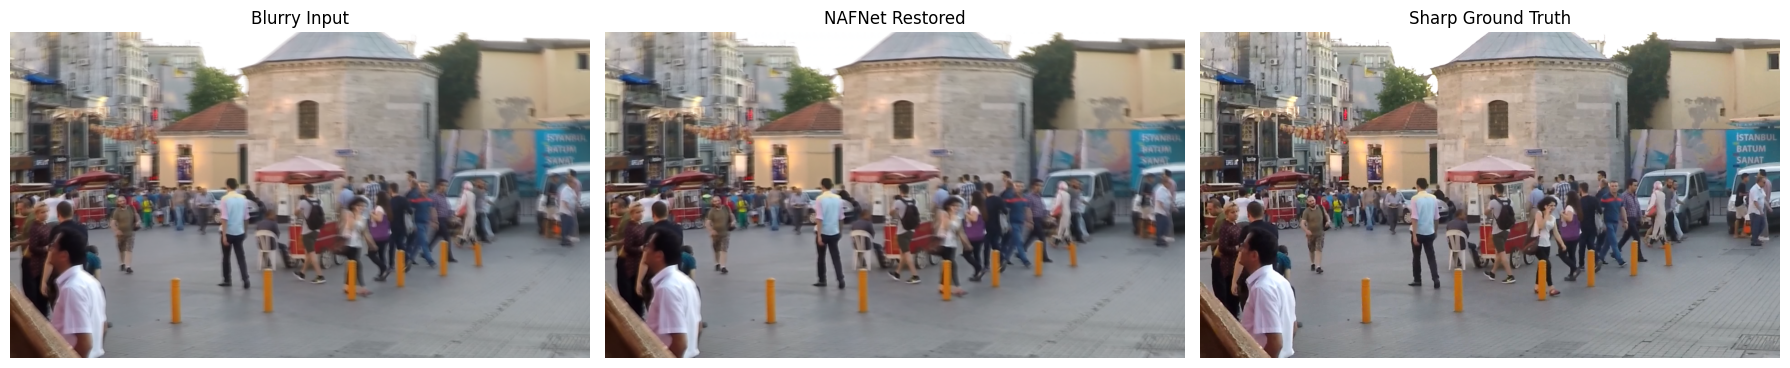

In [ ]:
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

name = "GOPR0384_11_00_000006.png"

blur = cv2.cvtColor(
    cv2.imread(f"datasets/GoPro/test/input/{name}"),
    cv2.COLOR_BGR2RGB
)

restored = cv2.cvtColor(
    cv2.imread(f"results/NAFNet-GoPro-T4/{name}"),
    cv2.COLOR_BGR2RGB
)

sharp = cv2.cvtColor(
    cv2.imread(f"datasets/GoPro/test/target/{name}"),
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(18, 6))

for i, (img, title) in enumerate([
    (blur, "Blurry Input"),
    (restored, "NAFNet Restored"),
    (sharp, "Sharp Ground Truth")
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()